# 🚀 Fine-tune `ViSoBERT` (`uitnlp/visobert`) cho Bài toán ABSA Thời Trang Tiếng Việt

**Tổng quan Notebook:**
- **Mô hình cơ sở (Backbone):** `uitnlp/visobert` (Vietnamese Social Media RoBERTa — ~135M tham số, sử dụng SentencePiece BPE chuyên xử lý bình luận MXH & TMĐT tiếng Việt có teencode, viết tắt, emoji mà không cần tách từ `pyvi`/`underthesea`).
- **Kiến trúc Multi-Task ABSA:** Mạng phân loại đa đầu ra (**5 Aspect Heads** $\times$ **4 Sentiment Classes** `[0: Không đề cập, 1: Tiêu cực, 2: Trung tính, 3: Tích cực]`) có tích hợp **Balanced Class Weights** để chống mất cân bằng nhãn `0`.
- **Dữ liệu (`data/external/FashionReviews.csv`):** 89,010 câu duy nhất sau khử trùng lặp, chia **85% Train (75,658 mẫu) / 15% Valid (13,352 mẫu)** với `random_state=42`, chuẩn hóa bằng `TextPreprocessor(mode="hybrid")` chống Data Leakage.
- **Tối ưu phần cứng (Google Colab GPU):** Sử dụng `bf16`/`fp16` Mixed Precision, huấn luyện **toàn bộ 100% tập dữ liệu (75,658 mẫu)** cực nhanh và tự động lưu **Best Model + Checkpoint + Báo cáo Macro-F1 + Kết quả suy luận trên tập Test Shopee** trực tiếp vào **Google Drive**.

## 1. Kết nối Google Drive & Kiểm tra GPU trên Google Colab

In [ ]:
import os
import torch
from google.colab import drive

# 1. Mount Google Drive để lưu model, checkpoints và báo cáo đánh giá
drive.mount('/content/drive')

DRIVE_BASE_DIR = "/content/drive/MyDrive/ABSA_Fashion_Models/visobert_absa"
CHECKPOINT_DIR = os.path.join(DRIVE_BASE_DIR, "checkpoints")
BEST_MODEL_DIR = os.path.join(DRIVE_BASE_DIR, "best_model")
REPORTS_DIR = os.path.join(DRIVE_BASE_DIR, "reports")

for d in [DRIVE_BASE_DIR, CHECKPOINT_DIR, BEST_MODEL_DIR, REPORTS_DIR]:
    os.makedirs(d, exist_ok=True)

# 2. Kiểm tra GPU
assert torch.cuda.is_available(), "❌ Không tìm thấy GPU! Vui lòng vào Runtime -> Change runtime type -> chọn GPU."
device = torch.device("cuda")
gpu_name = torch.cuda.get_device_name(0)
vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
use_bf16 = torch.cuda.is_bf16_supported()
print(f"✅ Đang sử dụng GPU: {gpu_name} | Tổng VRAM: {vram_gb:.2f} GB | Hỗ trợ BF16: {use_bf16}")
print(f"📂 Thư mục lưu kết quả trên Google Drive: {DRIVE_BASE_DIR}")

Mounted at /content/drive
✅ Đang sử dụng GPU: NVIDIA L4 | Tổng VRAM: 22.03 GB | Hỗ trợ BF16: True
📂 Thư mục lưu kết quả trên Google Drive: /content/drive/MyDrive/ABSA_Fashion_Models/visobert_absa


## 2. Cài đặt các Thư viện Cần thiết

In [ ]:
%%capture
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn sentencepiece

## 3. Cấu hình Hyperparameters & Đường dẫn Dữ liệu

In [ ]:
import random
import numpy as np

MODEL_NAME = "uitnlp/visobert"
ASPECT_COLS = ["Chất liệu", "Kiểu dáng", "Kích cỡ", "Giá cả", "Dịch vụ"]
LABEL_NAMES = ["0: Không đề cập", "1: Tiêu cực", "2: Trung tính", "3: Tích cực"]
NUM_ASPECTS = len(ASPECT_COLS)  # 5 khía cạnh
NUM_CLASSES = 4                 # 4 nhãn (0, 1, 2, 3)

# Phiên bản văn bản đầu vào ("text_C_hybrid", "text_B_rule", hoặc "text_A_minimal")
TEXT_VERSION = "text_C_hybrid"

# Hyperparameters chuẩn cho ViSoBERT (RoBERTa-base) trên tập 75,658 mẫu:
MAX_LEN = 256
TRAIN_BATCH_SIZE = 64     # Trên GPU 16GB-24GB VRAM, ViSoBERT chạy batch_size=64 rất nhẹ và nhanh
EVAL_BATCH_SIZE = 128
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
EPOCHS = 4
WARMUP_RATIO = 0.06
DROPOUT_PROB = 0.1
USE_CLASS_WEIGHTS = True  # Cân bằng trọng số loss theo tần suất nhãn trên tập Train để tối ưu Macro-F1
SEED = 42

# Đường dẫn dữ liệu trên Google Drive (Nếu chưa upload lên Drive, code sẽ tự động tải 'vinhplaykennen/FashionReviews' từ HuggingFace)
DRIVE_DATA_DIR = "/content/drive/MyDrive/ABSA_Fashion_Models/data"
CUSTOM_EXTERNAL_CSV = os.path.join(DRIVE_DATA_DIR, "FashionReviews.csv")
PREPROCESSED_TRAIN_CSV = os.path.join(DRIVE_DATA_DIR, "hf_train.csv")
PREPROCESSED_VALID_CSV = os.path.join(DRIVE_DATA_DIR, "hf_valid.csv")
SHOPEE_TEST_CSV = os.path.join(DRIVE_DATA_DIR, "shopee_test_preprocessed.csv")

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

## 4. Nạp Bộ Dữ liệu External (`FashionReviews.csv`) & Tiền xử lý Chống Data Leakage
- Tích hợp nguyên bản module `TextPreprocessor` (`src/preprocessing.py`) của dự án để chuẩn hóa Unicode NFC, nén ký tự lặp, giữ dấu câu cảm xúc (`!`, `?`) và chuẩn hóa Teencode đơn nghĩa bằng Lookaround Regex.
- Tuân thủ nghiêm ngặt quy trình chống Data Leakage: **Khử trùng lặp $\rightarrow$ Chia Train/Valid (85/15, `random_state=42`) $\rightarrow$ Fit chỉ trên Train $\rightarrow$ Transform lên Train & Valid**.

In [ ]:
import html
import re
import unicodedata
import pandas as pd
from sklearn.model_selection import train_test_split
from datasets import load_dataset

# --- Module Tiền xử lý Văn bản ABSA (Đồng bộ 100% với src/preprocessing.py) ---
SAFE_NORMALIZATION = {
    "khum": "không", "ko": "không", "hong": "không", "hok": "không", "k0": "không",
    "mik": "mình", "mk": "mình", "mn": "mọi người", "mng": "mọi người",
    "đc": "được", "dc": "được", "đk": "được", "sp": "sản phẩm", "sz": "size",
    "from": "form", "siu": "siêu", "qá": "quá", "cx": "cũng", "vs": "với",
    "ntn": "như thế nào", "nv": "nhân viên", "shop": "shop", "sốp": "shop",
    "oke": "ok", "okie": "ok", "ib": "nhắn tin", "rep": "trả lời",
    "ship": "giao hàng", "tks": "cảm ơn", "thank": "cảm ơn", "thanks": "cảm ơn",
}
AMBIGUOUS_TOKENS = frozenset({"k", "m", "đ", "b", "c", "e", "t", "s", "l"})
URL_RE = re.compile(r"(?:https?://\S+|www\.\S+)", re.IGNORECASE)
HTML_TAG_RE = re.compile(r"<[^>]+>")
MULTI_SPACE_RE = re.compile(r"[ \t\r\n]+")
REPEAT_CHAR_RE = re.compile(r"([^\W\d_])\1{2,}", re.UNICODE)
REPEAT_PUNCT_RE = re.compile(r"([!?.,])\1+")
DECOR_PUNCT_B_RE = re.compile(r"[^\w\s]", re.UNICODE)
DECOR_PUNCT_C_RE = re.compile(r"[^\w\s!?.,]", re.UNICODE)

_keys = sorted((k for k in SAFE_NORMALIZATION.keys() if k.lower() not in AMBIGUOUS_TOKENS), key=len, reverse=True)
SAFE_DICT_RE = re.compile(rf"(?<![^\W_])(?:{'|'.join(re.escape(k) for k in _keys)})(?![^\W_])", re.IGNORECASE | re.UNICODE)

def preprocess_text(raw_text: str, mode: str = "hybrid") -> str:
    if not raw_text:
        return ""
    text = unicodedata.normalize("NFC", html.unescape(str(raw_text)))
    text = HTML_TAG_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = MULTI_SPACE_RE.sub(" ", text)
    if mode == "minimal":
        return text.strip()

    text = REPEAT_CHAR_RE.sub(lambda m: m.group(1), text)
    if mode == "hybrid":
        text = REPEAT_PUNCT_RE.sub(lambda m: m.group(1), text)
        text = DECOR_PUNCT_C_RE.sub(" ", text)
        text = re.sub(r"\b(\d+)\s+(k|kg|cm)\b", lambda m: f"{m.group(1)}{m.group(2).lower()}", text, flags=re.IGNORECASE)
    else:
        text = DECOR_PUNCT_B_RE.sub(" ", text)

    text = SAFE_DICT_RE.sub(lambda m: SAFE_NORMALIZATION.get(m.group(0).lower(), m.group(0)), text)
    return MULTI_SPACE_RE.sub(" ", text).strip()

# --- Nạp hoặc Tạo Tập Train / Valid ---
if os.path.exists(PREPROCESSED_TRAIN_CSV) and os.path.exists(PREPROCESSED_VALID_CSV):
    print(f"📂 Đang nạp trực tiếp hf_train.csv & hf_valid.csv từ Google Drive...")
    train_df = pd.read_csv(PREPROCESSED_TRAIN_CSV)
    valid_df = pd.read_csv(PREPROCESSED_VALID_CSV)
else:
    if os.path.exists(CUSTOM_EXTERNAL_CSV):
        print(f"📂 Đang đọc FashionReviews.csv từ Google Drive: {CUSTOM_EXTERNAL_CSV}")
        df_hf = pd.read_csv(CUSTOM_EXTERNAL_CSV)
    else:
        print("🌐 Không tìm thấy file CSV trên Drive, đang tải trực tiếp 'vinhplaykennen/FashionReviews' từ HuggingFace...")
        hf_ds = load_dataset("vinhplaykennen/FashionReviews", split="train")
        df_hf = hf_ds.to_pandas()

    # 1. Xử lý NaN ở 5 cột nhãn & khử trùng lặp TRƯỚC khi chia Train/Valid
    for col in ASPECT_COLS:
        df_hf[col] = df_hf[col].fillna(0).astype(int)
    df_hf["Nội dung review"] = df_hf["Nội dung review"].fillna("").astype(str)
    df_hf = df_hf.drop_duplicates(subset=["Nội dung review"]).reset_index(drop=True)

    # 2. Chia Train / Valid (85% / 15%, random_state=42)
    train_df, valid_df = train_test_split(df_hf, test_size=0.15, random_state=SEED, shuffle=True)
    train_df = train_df.reset_index(drop=True)
    valid_df = valid_df.reset_index(drop=True)

    # 3. Tạo đủ 3 cột phiên bản tiền xử lý (A, B, C)
    for mode, col_name in [("minimal", "text_A_minimal"), ("rule_based", "text_B_rule"), ("hybrid", "text_C_hybrid")]:
        train_df[col_name] = [preprocess_text(t, mode=mode) for t in train_df["Nội dung review"]]
        valid_df[col_name] = [preprocess_text(t, mode=mode) for t in valid_df["Nội dung review"]]

    # Lưu bản đã tiền xử lý lên Google Drive để những lần chạy sau nạp tức thì
    os.makedirs(DRIVE_DATA_DIR, exist_ok=True)
    train_df.to_csv(PREPROCESSED_TRAIN_CSV, index=False, encoding="utf-8-sig")
    valid_df.to_csv(PREPROCESSED_VALID_CSV, index=False, encoding="utf-8-sig")
    print(f"💾 Đã lưu hf_train.csv & hf_valid.csv vào {DRIVE_DATA_DIR}")

for col in ASPECT_COLS:
    train_df[col] = train_df[col].fillna(0).astype(int)
    valid_df[col] = valid_df[col].fillna(0).astype(int)
train_df[TEXT_VERSION] = train_df[TEXT_VERSION].fillna("").astype(str)
valid_df[TEXT_VERSION] = valid_df[TEXT_VERSION].fillna("").astype(str)

print(f"✅ Tập Train: {len(train_df):,} mẫu | Tập Valid: {len(valid_df):,} mẫu | Cột văn bản: {TEXT_VERSION}")
train_df[[TEXT_VERSION] + ASPECT_COLS].head(5)

📂 Đang nạp trực tiếp hf_train.csv & hf_valid.csv từ Google Drive...
✅ Tập Train: 75,658 mẫu | Tập Valid: 13,352 mẫu | Cột văn bản: text_C_hybrid


,text_C_hybrid,Chất liệu,Kiểu dáng,Kích cỡ,Giá cả,Dịch vụ
0,Chất liệu mềm và nhẹ. Ảnh ở đây không thể hiện...,3,1,2,0,0
1,"Đúng như các đánh giá khác, chất vải mỏng dính...",1,0,0,2,0
2,"váy đẹp, mà không có size to hơn, size xl ghi ...",3,0,1,2,0
3,"Sản phẩm không đúng với mô tả, chất liệu vải t...",1,1,0,1,1
4,Hàng nhận được đóng gói như mới nhưng lại có v...,0,1,0,0,2


## 5. Xây dựng PyTorch Dataset & Tính Trọng số Cân bằng Nhãn (Class Weights)
Do nhãn `0: Không đề cập` chiếm `31.7% – 45.9%` trong khi nhãn `2: Trung tính` chỉ chiếm `12.9% – 18.1%`, việc tính **Class Weights riêng cho từng khía cạnh** trên tập Train giúp mô hình không bị thiên lệch về nhãn `0` và tăng mạnh chỉ số **Macro-F1**.

In [ ]:
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
from sklearn.utils.class_weight import compute_class_weight

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class FashionABSADataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len: int = 256):
        self.texts = list(texts)
        self.labels = np.array(labels, dtype=np.int64)  # Shape: (N, 5)
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors="pt",
        )
        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }

train_dataset = FashionABSADataset(
    texts=train_df[TEXT_VERSION].tolist(),
    labels=train_df[ASPECT_COLS].values,
    tokenizer=tokenizer,
    max_len=MAX_LEN,
)
valid_dataset = FashionABSADataset(
    texts=valid_df[TEXT_VERSION].tolist(),
    labels=valid_df[ASPECT_COLS].values,
    tokenizer=tokenizer,
    max_len=MAX_LEN,
)

train_loader = DataLoader(train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# Tính ma trận Class Weights kích thước (5 khía cạnh, 4 nhãn) chỉ từ tập Train
aspect_class_weights = []
print("📊 Trọng số Cân bằng Nhãn (Class Weights) trên từng khía cạnh:")
for col in ASPECT_COLS:
    y_col = train_df[col].values
    classes = np.array([0, 1, 2, 3])
    weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_col)
    # Làm mượt trọng số bằng căn bậc hai (Sqrt Smoothing) để ổn định gradient nhưng vẫn ưu tiên lớp thiểu số
    smooth_weights = np.sqrt(weights)
    smooth_weights = smooth_weights / smooth_weights.mean()
    aspect_class_weights.append(smooth_weights)
    print(f"  - {col:<10}: {[round(float(w), 3) for w in smooth_weights]}")

aspect_class_weights_tensor = torch.tensor(np.array(aspect_class_weights), dtype=torch.float32, device=device)

config.json:   0%|          | 0.00/644 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  471kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

📊 Trọng số Cân bằng Nhãn (Class Weights) trên từng khía cạnh:
  - Chất liệu : [0.781, 1.082, 1.21, 0.927]
  - Kiểu dáng : [0.838, 1.093, 1.159, 0.91]
  - Kích cỡ   : [0.851, 0.963, 1.31, 0.875]
  - Giá cả    : [0.683, 1.244, 1.088, 0.985]
  - Dịch vụ   : [0.769, 1.064, 1.313, 0.854]


## 6. Kiến trúc Mô hình Multi-Task `ViSoBERTForABSA`
- Kết hợp **Mean Pooling + CLS Pooling** trên tầng ẩn cuối cùng của `ViSoBERT`, sau đó đưa qua **5 nhánh phân loại (5 Aspect Classification Heads)** độc lập để dự đoán đồng thời 5 khía cạnh trong 1 lần forward duy nhất.

In [ ]:
import torch.nn as nn
from transformers import AutoConfig, AutoModel

class ViSoBERTForABSA(nn.Module):
    def __init__(
        self,
        model_name: str = MODEL_NAME,
        num_aspects: int = NUM_ASPECTS,
        num_classes: int = NUM_CLASSES,
        dropout_prob: float = DROPOUT_PROB,
    ):
        super().__init__()
        self.config = AutoConfig.from_pretrained(model_name)
        self.backbone = AutoModel.from_pretrained(model_name, config=self.config)
        hidden_size = self.config.hidden_size

        # Kết hợp [CLS] token và Mean Pooling -> kích thước vector đặc trưng = hidden_size * 2
        self.dropout = nn.Dropout(dropout_prob)
        self.aspect_heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_size * 2, hidden_size),
                nn.GELU(),
                nn.Dropout(dropout_prob),
                nn.Linear(hidden_size, num_classes),
            )
            for _ in range(num_aspects)
        ])

    def forward(self, input_ids, attention_mask, labels=None, class_weights=None):
        outputs = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        seq_output = outputs.last_hidden_state  # (B, L, H)

        # 1. Vector [CLS] ở đầu câu
        cls_repr = seq_output[:, 0, :]

        # 2. Mean Pooling trên các token không phải padding
        mask_expanded = attention_mask.unsqueeze(-1).expand(seq_output.size()).float()
        sum_embeddings = torch.sum(seq_output * mask_expanded, dim=1)
        sum_mask = mask_expanded.sum(dim=1).clamp(min=1e-9)
        mean_repr = sum_embeddings / sum_mask

        pooled = self.dropout(torch.cat([cls_repr, mean_repr], dim=-1))  # (B, 2H)

        # Tính logits cho 5 khía cạnh -> stacked shape: (B, 5, 4)
        logits_list = [head(pooled) for head in self.aspect_heads]
        logits = torch.stack(logits_list, dim=1)

        loss = None
        if labels is not None:
            total_loss = 0.0
            for i in range(len(self.aspect_heads)):
                w = class_weights[i] if class_weights is not None else None
                criterion = nn.CrossEntropyLoss(weight=w)
                total_loss = total_loss + criterion(logits[:, i, :], labels[:, i])
            loss = total_loss / len(self.aspect_heads)

        return {"loss": loss, "logits": logits}

model = ViSoBERTForABSA(MODEL_NAME).to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"✅ Đã khởi tạo ViSoBERTForABSA | Tổng tham số: {total_params:,} | Tham số huấn luyện: {trainable_params:,}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  390MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: uitnlp/visobert
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Đã khởi tạo ViSoBERTForABSA | Tổng tham số: 103,483,412 | Tham số huấn luyện: 103,483,412


## 7. Hàm Đánh giá Chi tiết (Macro-F1, Sentiment-Only F1 & Accuracy trên 5 Khía cạnh)
- Tính đầy đủ:
  1. **Overall Macro-F1 (4 nhãn `0, 1, 2, 3`)**: Thước đo chính của bài toán End-to-End ABSA.
  2. **Aspect Detection F1 (Nhị phân `Có đề cập` vs `Không đề cập`)**: Đánh giá khả năng phát hiện khía cạnh.
  3. **Sentiment-Only Macro-F1 (3 nhãn `1: Tiêu cực, 2: Trung tính, 3: Tích cực`)**: Đánh giá độ chuẩn xác phân loại cảm xúc trên các câu thực sự có nhắc tới khía cạnh.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

@torch.no_grad()
def evaluate_model(model, data_loader):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_labels = []
    amp_dtype = torch.bfloat16 if use_bf16 else torch.float16

    for batch in data_loader:
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)

        with torch.cuda.amp.autocast(dtype=amp_dtype):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
                class_weights=aspect_class_weights_tensor if USE_CLASS_WEIGHTS else None,
            )
            loss = outputs["loss"]
            logits = outputs["logits"]

        total_loss += loss.item() * input_ids.size(0)
        preds = torch.argmax(logits, dim=-1).cpu().numpy()
        all_preds.append(preds)
        all_labels.append(labels.cpu().numpy())

    avg_loss = total_loss / len(data_loader.dataset)
    all_preds = np.concatenate(all_preds, axis=0)   # (N, 5)
    all_labels = np.concatenate(all_labels, axis=0) # (N, 5)

    rows = []
    for i, col in enumerate(ASPECT_COLS):
        y_true = all_labels[:, i]
        y_pred = all_preds[:, i]

        acc = accuracy_score(y_true, y_pred) * 100
        macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0) * 100
        weighted_f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0) * 100

        # Aspect Detection F1 (0 vs >0)
        det_true = (y_true > 0).astype(int)
        det_pred = (y_pred > 0).astype(int)
        aspect_det_f1 = f1_score(det_true, det_pred, average="binary", zero_division=0) * 100

        # Sentiment-Only Macro-F1 (trên các mẫu thực sự có đề cập y_true > 0)
        sent_mask = y_true > 0
        if sent_mask.sum() > 0:
            sent_f1 = f1_score(
                y_true[sent_mask],
                y_pred[sent_mask],
                labels=[1, 2, 3],
                average="macro",
                zero_division=0,
            ) * 100
        else:
            sent_f1 = 0.0

        rows.append({
            "Khía cạnh": col,
            "Accuracy (%)": round(acc, 2),
            "Macro-F1 4 nhãn (%)": round(macro_f1, 2),
            "Weighted-F1 (%)": round(weighted_f1, 2),
            "Aspect Detection F1 (%)": round(aspect_det_f1, 2),
            "Sentiment-Only F1 (%)": round(sent_f1, 2),
        })

    metrics_df = pd.DataFrame(rows)
    mean_macro_f1 = float(metrics_df["Macro-F1 4 nhãn (%)"].mean())
    mean_acc = float(metrics_df["Accuracy (%)"].mean())

    avg_row = pd.DataFrame([{
        "Khía cạnh": "TRUNG BÌNH (OVERALL)",
        "Accuracy (%)": round(mean_acc, 2),
        "Macro-F1 4 nhãn (%)": round(mean_macro_f1, 2),
        "Weighted-F1 (%)": round(float(metrics_df["Weighted-F1 (%)"].mean()), 2),
        "Aspect Detection F1 (%)": round(float(metrics_df["Aspect Detection F1 (%)"].mean()), 2),
        "Sentiment-Only F1 (%)": round(float(metrics_df["Sentiment-Only F1 (%)"].mean()), 2),
    }])
    metrics_df = pd.concat([metrics_df, avg_row], ignore_index=True)

    return {
        "val_loss": avg_loss,
        "mean_macro_f1": mean_macro_f1,
        "mean_acc": mean_acc,
        "metrics_df": metrics_df,
        "preds": all_preds,
        "labels": all_labels,
    }

## 8. Vòng lặp Huấn luyện (Mixed Precision + Cosine Scheduler + Tự động Resume & Lưu Best Model lên Google Drive)
- Sau mỗi Epoch, hệ thống tự động lưu `latest_checkpoint.pt` vào Google Drive (để nếu Colab bị ngắt kết nối, chạy lại cell sẽ tự tiếp tục từ Epoch dở dang).
- Khi đạt `Macro-F1` cao nhất trên tập Valid, toàn bộ trọng số mô hình (`visobert_absa_weights.pt`), `config.json`, `tokenizer`, và bảng điểm CSV sẽ được lưu vào `BEST_MODEL_DIR` trên Google Drive.

In [ ]:
import json
import time
from tqdm.auto import tqdm
from transformers import get_cosine_schedule_with_warmup

# Phân tách nhóm tham số để không áp dụng weight_decay lên bias và LayerNorm
no_decay = ["bias", "LayerNorm.weight"]
optimizer_grouped_parameters = [
    {
        "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
        "weight_decay": 0.0,
    },
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters, lr=LEARNING_RATE)
total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)

amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
scaler = torch.cuda.amp.GradScaler(enabled=not use_bf16)

latest_ckpt_path = os.path.join(CHECKPOINT_DIR, "latest_checkpoint.pt")
start_epoch = 1
best_macro_f1 = 0.0
history = []

# Tự động khôi phục từ Google Drive nếu phiên Colab trước bị ngắt giữa chừng
if os.path.exists(latest_ckpt_path):
    print(f"🔄 Phát hiện checkpoint trên Google Drive: {latest_ckpt_path}")
    ckpt = torch.load(latest_ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    start_epoch = ckpt["epoch"] + 1
    best_macro_f1 = ckpt.get("best_macro_f1", 0.0)
    history = ckpt.get("history", [])
    print(f"✅ Đã khôi phục thành công! Tiếp tục từ Epoch {start_epoch}/{EPOCHS} (Best Macro-F1 hiện tại: {best_macro_f1:.2f}%)")

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    epoch_start = time.time()

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]")
    for step, batch in enumerate(pbar, start=1):
        optimizer.zero_grad(set_to_none=True)

        input_ids = batch["input_ids"].to(device, non_blocking=True)
        attention_mask = batch["attention_mask"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)

        with torch.cuda.amp.autocast(dtype=amp_dtype):
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels,
                class_weights=aspect_class_weights_tensor if USE_CLASS_WEIGHTS else None,
            )
            loss = outputs["loss"]

        if use_bf16:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        else:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

        scheduler.step()
        running_loss += loss.item() * input_ids.size(0)

        if step % 50 == 0 or step == len(train_loader):
            pbar.set_postfix({
                "loss": f"{loss.item():.4f}",
                "lr": f"{scheduler.get_last_lr()[0]:.2e}",
            })

    train_loss = running_loss / len(train_loader.dataset)
    eval_res = evaluate_model(model, valid_loader)
    val_loss = eval_res["val_loss"]
    val_macro_f1 = eval_res["mean_macro_f1"]
    val_acc = eval_res["mean_acc"]
    elapsed = time.time() - epoch_start

    print(f"\n📌 [Epoch {epoch}/{EPOCHS}] Thời gian: {elapsed:.1f}s | Train Loss: {train_loss:.4f} | Valid Loss: {val_loss:.4f} | Valid Acc: {val_acc:.2f}% | Valid Macro-F1: {val_macro_f1:.2f}%")
    display(eval_res["metrics_df"])

    history.append({
        "epoch": epoch,
        "train_loss": round(train_loss, 4),
        "val_loss": round(val_loss, 4),
        "val_accuracy": round(val_acc, 2),
        "val_macro_f1": round(val_macro_f1, 2),
        "time_sec": round(elapsed, 1),
    })

    # 1. Lưu Best Model vào Google Drive nếu Macro-F1 cải thiện
    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1
        print(f"🏆 Kỷ lục Macro-F1 mới ({best_macro_f1:.2f}%)! Đang lưu Best Model vào Google Drive: {BEST_MODEL_DIR}")
        torch.save(model.state_dict(), os.path.join(BEST_MODEL_DIR, "visobert_absa_weights.pt"))
        tokenizer.save_pretrained(BEST_MODEL_DIR)
        model.config.save_pretrained(BEST_MODEL_DIR)
        eval_res["metrics_df"].to_csv(os.path.join(REPORTS_DIR, "visobert_best_valid_metrics.csv"), index=False, encoding="utf-8-sig")
        with open(os.path.join(BEST_MODEL_DIR, "training_metadata.json"), "w", encoding="utf-8") as f:
            json.dump({
                "backbone": MODEL_NAME,
                "text_version": TEXT_VERSION,
                "max_len": MAX_LEN,
                "best_epoch": epoch,
                "best_val_macro_f1": round(best_macro_f1, 2),
                "best_val_accuracy": round(val_acc, 2),
                "aspect_cols": ASPECT_COLS,
                "history": history,
            }, f, ensure_ascii=False, indent=2)

    # 2. Cập nhật latest_checkpoint.pt trên Google Drive sau mỗi Epoch
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_macro_f1": best_macro_f1,
        "history": history,
    }, latest_ckpt_path)
    pd.DataFrame(history).to_csv(os.path.join(REPORTS_DIR, "training_history.csv"), index=False, encoding="utf-8-sig")

print(f"\n🎉 Hoàn tất huấn luyện! Best Validation Macro-F1: {best_macro_f1:.2f}% (Đã lưu tại {BEST_MODEL_DIR})")

/tmp/ipykernel_1169/415058997.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=not use_bf16)


model.safetensors: reconstructing file:   0%|          |  0.00B /  390MB            

model.safetensors: downloading bytes:           |  0.00B            

🔄 Phát hiện checkpoint trên Google Drive: /content/drive/MyDrive/ABSA_Fashion_Models/visobert_absa/checkpoints/latest_checkpoint.pt
✅ Đã khôi phục thành công! Tiếp tục từ Epoch 2/4 (Best Macro-F1 hiện tại: 87.52%)


Epoch 2/4 [Train]:   0%|          | 0/1183 [00:00<?, ?it/s]

/tmp/ipykernel_1169/415058997.py:57: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=amp_dtype):
/tmp/ipykernel_1169/360042035.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=amp_dtype):


... (9 outputs left out)

/tmp/ipykernel_1169/415058997.py:57: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=amp_dtype):
/tmp/ipykernel_1169/360042035.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=amp_dtype):



📌 [Epoch 4/4] Thời gian: 512.4s | Train Loss: 0.1984 | Valid Loss: 0.2666 | Valid Acc: 90.68% | Valid Macro-F1: 89.40%


,Khía cạnh,Accuracy (%),Macro-F1 4 nhãn (%),Weighted-F1 (%),Aspect Detection F1 (%),Sentiment-Only F1 (%)
0,Chất liệu,90.67,89.96,90.67,96.16,90.69
1,Kiểu dáng,90.35,90.22,90.37,96.17,91.39
2,Kích cỡ,87.33,84.81,87.29,97.12,83.11
3,Giá cả,93.60,91.93,93.59,98.44,90.74
4,Dịch vụ,91.43,90.08,91.43,95.92,91.04
5,TRUNG BÌNH (OVERALL),90.68,89.40,90.67,96.76,89.39


🏆 Kỷ lục Macro-F1 mới (89.40%)! Đang lưu Best Model vào Google Drive: /content/drive/MyDrive/ABSA_Fashion_Models/visobert_absa/best_model

🎉 Hoàn tất huấn luyện! Best Validation Macro-F1: 89.40% (Đã lưu tại /content/drive/MyDrive/ABSA_Fashion_Models/visobert_absa/best_model)


## 9. Kiểm tra Chi tiết Best Model (Classification Report & Confusion Matrix trên Tập Valid)

/tmp/ipykernel_1169/360042035.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=amp_dtype):


=== BẢNG TỔNG HỢP KẾT QUẢ BEST VISOBERT MODEL TRÊN TẬP VALIDATION (13,352 MẪU) ===


,Khía cạnh,Accuracy (%),Macro-F1 4 nhãn (%),Weighted-F1 (%),Aspect Detection F1 (%),Sentiment-Only F1 (%)
0,Chất liệu,90.67,89.96,90.67,96.16,90.69
1,Kiểu dáng,90.35,90.22,90.37,96.17,91.39
2,Kích cỡ,87.33,84.81,87.29,97.12,83.11
3,Giá cả,93.60,91.93,93.59,98.44,90.74
4,Dịch vụ,91.43,90.08,91.43,95.92,91.04
5,TRUNG BÌNH (OVERALL),90.68,89.40,90.67,96.76,89.39


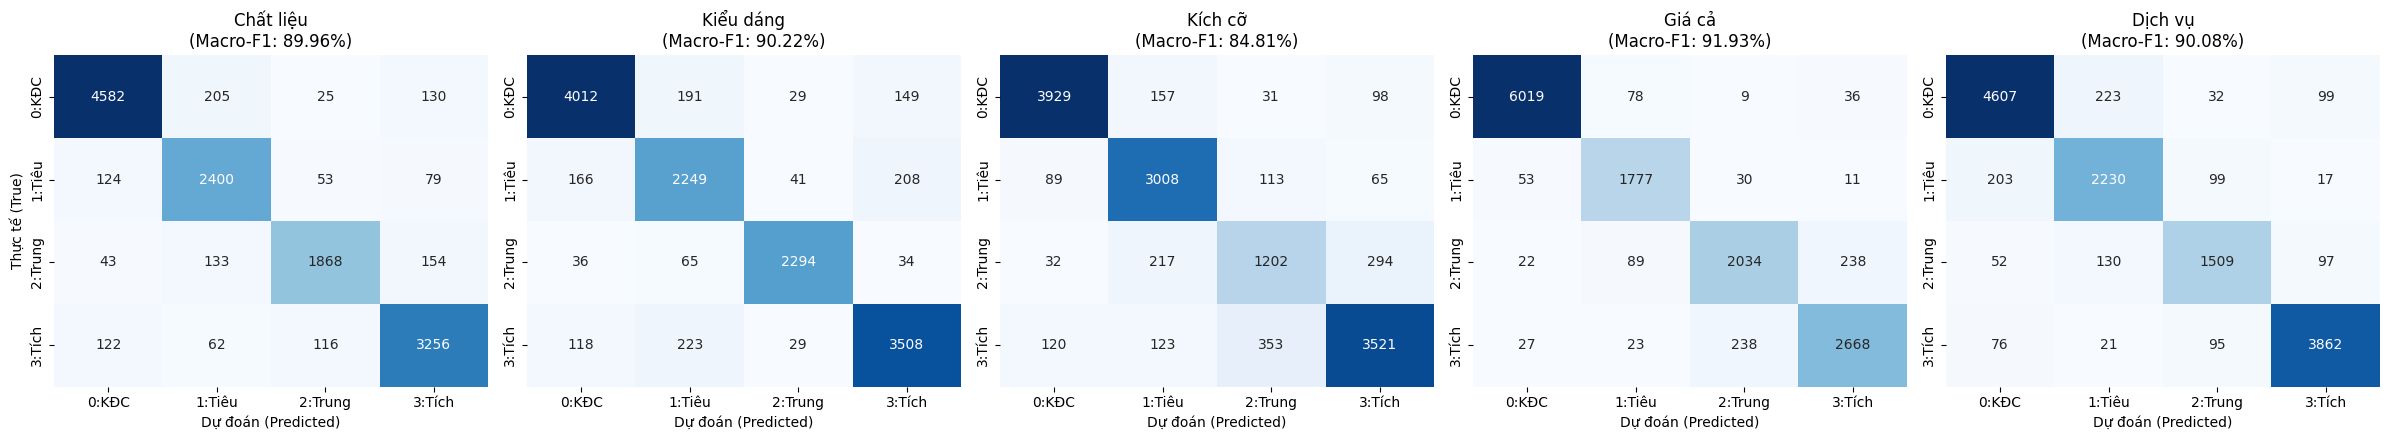

🖼️ Đã lưu biểu đồ Confusion Matrix vào Google Drive: /content/drive/MyDrive/ABSA_Fashion_Models/visobert_absa/reports/visobert_confusion_matrices.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Nạp lại trọng số Best Model từ Google Drive
best_weights_path = os.path.join(BEST_MODEL_DIR, "visobert_absa_weights.pt")
model.load_state_dict(torch.load(best_weights_path, map_location=device))
best_eval = evaluate_model(model, valid_loader)

print("=== BẢNG TỔNG HỢP KẾT QUẢ BEST VISOBERT MODEL TRÊN TẬP VALIDATION (13,352 MẪU) ===")
display(best_eval["metrics_df"])

# Vẽ Confusion Matrix cho cả 5 khía cạnh và lưu ảnh chất lượng cao vào Google Drive
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
short_labels = ["0:KĐC", "1:Tiêu", "2:Trung", "3:Tích"]

for i, col in enumerate(ASPECT_COLS):
    cm = confusion_matrix(best_eval["labels"][:, i], best_eval["preds"][:, i], labels=[0, 1, 2, 3])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=short_labels, yticklabels=short_labels, ax=axes[i], cbar=False)
    axes[i].set_title(f"{col}\n(Macro-F1: {best_eval['metrics_df'].loc[i, 'Macro-F1 4 nhãn (%)']}%)")
    axes[i].set_xlabel("Dự đoán (Predicted)")
    if i == 0:
        axes[i].set_ylabel("Thực tế (True)")

plt.tight_layout()
cm_fig_path = os.path.join(REPORTS_DIR, "visobert_confusion_matrices.png")
plt.savefig(cm_fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"🖼️ Đã lưu biểu đồ Confusion Matrix vào Google Drive: {cm_fig_path}")

## 10. Chạy Suy luận Thử nghiệm & Dự đoán trên Tập Test Shopee (`shopee_test_preprocessed.csv`)
- Nếu bạn đã upload file `shopee_test_preprocessed.csv` (hoặc `shopee_absa_reviews_flat.csv`) lên thư mục `/content/drive/MyDrive/ABSA_Fashion_Models/data/`, cell dưới sẽ tự động gán nhãn 5 khía cạnh cho toàn bộ bình luận Shopee và xuất kết quả ra Google Drive.

In [ ]:
ID2LABEL_TEXT = {0: "Không đề cập", 1: "Tiêu cực", 2: "Trung tính", 3: "Tích cực"}

@torch.no_grad()
def predict_reviews(raw_texts: list[str], batch_size: int = 128) -> pd.DataFrame:
    model.eval()
    norm_texts = [preprocess_text(t, mode="hybrid") for t in raw_texts]
    all_preds = []
    amp_dtype = torch.bfloat16 if use_bf16 else torch.float16

    for i in range(0, len(norm_texts), batch_size):
        batch_texts = norm_texts[i : i + batch_size]
        enc = tokenizer(
            batch_texts,
            truncation=True,
            max_length=MAX_LEN,
            padding=True,
            return_tensors="pt",
        ).to(device)
        with torch.cuda.amp.autocast(dtype=amp_dtype):
            logits = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])["logits"]
        preds = torch.argmax(logits, dim=-1).cpu().numpy()
        all_preds.append(preds)

    all_preds = np.concatenate(all_preds, axis=0)
    out_df = pd.DataFrame({"review_text": raw_texts, "text_C_hybrid": norm_texts})
    for idx, col in enumerate(ASPECT_COLS):
        out_df[col] = all_preds[:, idx]
        out_df[f"{col}_label"] = [ID2LABEL_TEXT[val] for val in all_preds[:, idx]]
    return out_df

# 1. Kiểm thử nhanh trên một số câu bình luận Shopee đặc trưng (có teencode, viết tắt)
sample_reviews = [
    "Vải mát lắm nha sốp, mặc lên form chuẩn đét, giao hàng siêu nhanh mỗi tội giá hơi chát xíu!",
    "Áo mỏng dính như tờ giấy, đặt sz M mà rộng thùng thình như XL, nhắn tin shop ko thèm rep luôn.",
    "Hàng chuẩn hình, đường may chắc chắn, săn sale có 85k quá hời, sẽ ủng hộ shop dài dài.",
]
print("=== DEMO DỰ ĐOÁN TRỰC TIẾP VỚI VISOBERT ===")
display(predict_reviews(sample_reviews)[["review_text"] + [f"{c}_label" for c in ASPECT_COLS]])

# 2. Tự động dự đoán trên tập Test Shopee nếu có file trên Google Drive
if os.path.exists(SHOPEE_TEST_CSV):
    print(f"\n📂 Phát hiện tập Test Shopee tại {SHOPEE_TEST_CSV}, đang chạy dự đoán toàn bộ tập Test...")
    shopee_df = pd.read_csv(SHOPEE_TEST_CSV)
    raw_col = "review_text" if "review_text" in shopee_df.columns else shopee_df.columns[0]
    pred_shopee = predict_reviews(shopee_df[raw_col].fillna("").astype(str).tolist())
    for col in ASPECT_COLS:
        shopee_df[f"pred_{col}"] = pred_shopee[col]
        shopee_df[f"pred_{col}_label"] = pred_shopee[f"{col}_label"]
    shopee_out_path = os.path.join(REPORTS_DIR, "shopee_test_visobert_predictions.csv")
    shopee_df.to_csv(shopee_out_path, index=False, encoding="utf-8-sig")
    print(f"✅ Đã lưu kết quả dự đoán trên tập Test Shopee vào Google Drive: {shopee_out_path}")

=== DEMO DỰ ĐOÁN TRỰC TIẾP VỚI VISOBERT ===


/tmp/ipykernel_1169/281066507.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=amp_dtype):


,review_text,Chất liệu_label,Kiểu dáng_label,Kích cỡ_label,Giá cả_label,Dịch vụ_label
0,"Vải mát lắm nha sốp, mặc lên form chuẩn đét, g...",Tích cực,Tích cực,Không đề cập,Tiêu cực,Tích cực
1,"Áo mỏng dính như tờ giấy, đặt sz M mà rộng thù...",Tiêu cực,Không đề cập,Tiêu cực,Không đề cập,Tiêu cực
2,"Hàng chuẩn hình, đường may chắc chắn, săn sale...",Không đề cập,Tích cực,Không đề cập,Tích cực,Tích cực
